<a href="https://colab.research.google.com/github/sidmoor/Predicting-Breakout-Success-of-Emerging-Artists/blob/main/logistic_model_training_and_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Project Overview

Objective

The objective of this analysis is to develop a Logistic Regression classification model that predicts whether an artist will experience sustained listener growth following a music release.

The model uses pre-release listening behavior, audience engagement, release history, and artist characteristics to estimate the probability that listener activity will remain elevated after a release.

Target Variable

The target variable is sustained, a binary indicator representing whether listener activity remains at least 20% above the artist's pre-release baseline during the later post-release observation period.

1: Sustained listener growth

0: No sustained listener growth

Modeling Approach

Logistic Regression was selected because the target variable is binary and the model provides interpretable predicted probabilities.

The analysis uses 10 pre-release predictor features and evaluates performance using accuracy, precision, recall, F1-score, ROC-AUC, and PR-AUC.

Because sustained-growth releases represent the minority class, particular attention is given to precision, recall, and PR-AUC.

The classification threshold is selected using validation data rather than relying exclusively on the default 0.50 threshold.

Data Source

The dataset combines ListenBrainz listening activity with MusicBrainz release metadata. Each observation represents an artist release.

The analysis focuses on clean releases and uses chronological training, validation, and testing periods to evaluate model generalization.

1. Load the data
What this does: Reads the processed artist-release dataset. Upload release_dataset.csv to Colab using the Files sidebar or place it alongside the notebook. low_memory=False lets pandas inspect mixed-type columns in one pass; it does not fix or recover an incomplete file.

In [1]:
import pandas as pd
# Reload the full dataset
df = pd.read_csv("release_dataset.csv")

# Verify the full dataset loaded
print("Dataset shape:", df.shape)

print("\nData splits:")
print(df["split"].value_counts(dropna=False))

Dataset shape: (67018, 69)

Data splits:
split
train    53593
val      13425
Name: count, dtype: int64


/tmp/ipykernel_2185/1338851501.py:3: DtypeWarning: Columns (38,53,65,67) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("release_dataset.csv")


In [5]:
from pathlib import Path
import numpy as np
import pandas as pd

DATA_PATH = Path("/content/release_dataset.csv")  # Colab upload location
if not DATA_PATH.exists():
    DATA_PATH = Path("release_dataset.csv")  # Jupyter/local fallback

if not DATA_PATH.exists():
    raise FileNotFoundError("Upload release_dataset.csv to Colab, then rerun this cell.")

df = pd.read_csv(DATA_PATH, low_memory=False)
df["release_date"] = pd.to_datetime(df["release_date"], errors="coerce")

print("Loaded file:", DATA_PATH.resolve())
print("Rows and columns:", df.shape)
print("Release date range:", df["release_date"].min(), "to", df["release_date"].max())
display(df.head(3))

Loaded file: /content/release_dataset.csv
Rows and columns: (112415, 69)
Release date range: 2021-03-25 00:00:00 to 2026-08-12 00:00:00


,artist_mbid,artist_credit_name,release_group_mbid,release_mbid,release_name,release_type,release_date,t0_week,split,is_clean,...,n_genres,primary_genre,n_tracks,labels,label_class,release_dow,is_friday_release,release_month,is_q4,sample_weight
0,016fcdc6-e7fa-4272-a28d-f54d890ac771,Russ Millions & Tion Wayne,a99fd3c3-ccfa-4078-82a9-8155fc6e1ec1,33d54842-5bca-48c1-8542-585b91d7ccb7,Body,Single,2021-03-25,2021-03-26,train,True,...,0,NaN,1.0,Atlantic Records UK,major,3,False,3,False,0.301511
1,02761fb1-8db3-4df4-8d43-6defb0e17abf,Хаски,494d743d-9206-4e3b-952b-dfe2f53437be,5673ef1b-3ef7-41a0-8c97-853023a34301,За Байкалом,Single,2021-03-25,2021-03-26,train,False,...,2,hip-hop,1.0,[no label],self-released,3,False,3,False,0.353553
2,0cebaa51-3787-423a-a287-4c7607ff0ee8,T & Sugah & Quoone,7ea60f16-66b5-4095-aa26-36464c9c9294,d5254bb5-d6af-4d10-8d27-779a942ed8d1,Leaving,Single,2021-03-25,2021-03-26,train,False,...,2,electronic,1.0,High Tea Music,independent,3,False,3,False,0.235702


2. Check the dataset and the chronological splits
What this does: Confirms that training, validation, and test releases exist before any modeling. The complete shared CSV has 112,415 rows (53,593 train, 22,782 validation, and 36,040 test). If your output differs, investigate the copy you loaded before using its test results in the report. This is especially important because an earlier Colab copy was missing some test rows.

In [6]:
print("Split counts:")
print(df["split"].value_counts(dropna=False))
print("\nClean releases by split:")
print(pd.crosstab(df["split"], df["is_clean"], dropna=False))
print("\nMissing target:", df["sustained"].isna().sum())

EXPECTED = {"train": 53593, "val": 22782, "test": 36040}
counts = df["split"].value_counts().to_dict()
if len(df) != 112415 or any(counts.get(k) != v for k, v in EXPECTED.items()):
    print("\nWARNING: This is not the complete 112,415-row CSV. Resolve before FINAL test reporting.")
else:
    print("\nFull uploaded dataset verified.")

assert {"train", "val", "test"}.issubset(set(df["split"].dropna())), "Missing a data split."
assert df["sustained"].notna().all(), "Target has missing values."
assert df["release_date"].notna().all(), "Release dates could not all be parsed."

Split counts:
split
train    53593
test     36040
val      22782
Name: count, dtype: int64

Clean releases by split:
is_clean  False  True 
split                 
test      12636  23404
train     19207  34386
val        8529  14253

Missing target: 0

Full uploaded dataset verified.


3. Define the target and the 10 predictors
What this does: Separates the outcome (y) from features (X). The outcome is binary. All predictors are intended to be known before a release; we exclude post-release columns (post_listeners_4w, log_lift_4w, late_lift_8_11w, etc.) because using them would leak the answer.
Category	Predictor	What it represents
Audience size	pre_listeners_12w	Mean weekly listeners in the 12 weeks before release
Momentum	pre_listener_slope_12w	Pre-release trend
Momentum	pre_growth_4v8	Recent four weeks relative to earlier eight
Stability	pre_listener_cv_12w	Week-to-week variability
Engagement	pre_listens_per_listener	Average listening depth
Engagement	pre_repeat_listener_ratio	Repeat-listener share
Release history	n_prior_releases	Number of previous releases
Release history	days_since_last_release	Gap since preceding release
Release characteristics	release_type	Album, EP, or single
Artist profile	primary_genre	Broad genre category


Modeling choice: A small, interpretable baseline. These features are not guaranteed to be the best possible selection.

In [7]:
features = [
    "pre_listeners_12w", "pre_listener_slope_12w", "pre_growth_4v8",
    "pre_listener_cv_12w", "pre_listens_per_listener",
    "pre_repeat_listener_ratio", "n_prior_releases",
    "days_since_last_release", "release_type", "primary_genre"
]
numeric_features = features[:8]
categorical_features = features[8:]

missing_cols = [c for c in features + ["sustained", "split", "is_clean"] if c not in df.columns]
if missing_cols:
    raise KeyError(f"Columns not found: {missing_cols}")

X = df[features].copy()
y = df["sustained"].astype(int)
print("10 selected feature names:", features)
print("\nFeature missingness (%):")
display((X.isna().mean() * 100).round(2).sort_values(ascending=False).to_frame("missing_pct"))
print("\nOutcome counts (all releases):")
print(y.value_counts())

10 selected feature names: ['pre_listeners_12w', 'pre_listener_slope_12w', 'pre_growth_4v8', 'pre_listener_cv_12w', 'pre_listens_per_listener', 'pre_repeat_listener_ratio', 'n_prior_releases', 'days_since_last_release', 'release_type', 'primary_genre']

Feature missingness (%):


,missing_pct
primary_genre,23.48
days_since_last_release,2.36
pre_listener_slope_12w,0.00
pre_listeners_12w,0.00
pre_growth_4v8,0.00
pre_listener_cv_12w,0.00
pre_repeat_listener_ratio,0.00
pre_listens_per_listener,0.00
n_prior_releases,0.00
release_type,0.00



Outcome counts (all releases):
sustained
0    87028
1    25387
Name: count, dtype: int64


4. Restrict to clean releases and split by time
What this does: Uses only releases flagged is_clean, reducing overlap with nearby releases. The provided split labels follow release date: training 2021–2023, validation 2024, and test 2025 onward. We do not shuffle time periods into a random split.

Important: Focusing on clean releases is a modeling design choice; it reduces some overlap but can change which releases the model represents.

In [8]:
clean = df["is_clean"].eq(True)
train_idx = df.index[clean & df["split"].eq("train")]
val_idx = df.index[clean & df["split"].eq("val")]
test_idx = df.index[clean & df["split"].eq("test")]

X_train, y_train = X.loc[train_idx], y.loc[train_idx]
X_val, y_val = X.loc[val_idx], y.loc[val_idx]
X_test, y_test = X.loc[test_idx], y.loc[test_idx]

for name, Xpart, ypart in [("Train", X_train, y_train), ("Validation", X_val, y_val), ("Test", X_test, y_test)]:
    print(f"{name}: {Xpart.shape[0]:,} releases, {Xpart.shape[1]} original features, "
          f"positive share={ypart.mean():.1%}")

assert all(len(part) > 0 for part in (X_train, X_val, X_test))
assert X_train.index.is_unique and X_val.index.is_unique and X_test.index.is_unique

Train: 34,386 releases, 10 original features, positive share=21.5%
Validation: 14,253 releases, 10 original features, positive share=19.4%
Test: 23,404 releases, 10 original features, positive share=23.7%


5. Build preprocessing that avoids leakage
What this does: For numerical features, fills missing values with the training median and scales each to mean 0 / standard deviation 1 (using training statistics). For categorical features, fills missing categories and one-hot encodes them. Unseen categories in validation or test are safely ignored.

The pipeline learns these transformations only when fitting on the training set, not from validation or test data.

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numerical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer([
    ("num", numerical_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features),
])
print("Preprocessing ready (not yet fitted).")

Preprocessing ready (not yet fitted).


6. Train the baseline Logistic Regression model
What this does: Fits a regularized Logistic Regression classifier using training data only. max_iter=1000 allows the optimization more steps if needed. This is the standard, unweighted model, corresponding to log_reg_model in our earlier exploration. Changing a prediction cutoff later does not retrain this model.

In [10]:
from sklearn.linear_model import LogisticRegression

log_reg_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42)),
])
log_reg_model.fit(X_train, y_train)
print("Standard Logistic Regression fitted on training data.")

Standard Logistic Regression fitted on training data.


7. Predict on validation data and evaluate the default 0.50 cutoff
What this does: Produces (a) predicted probabilities of sustained growth and (b) class labels using the default 50% probability cutoff. We evaluate on 2024 validation data, which was not used to train the model.

Metrics: Precision = reliability of positive flags; recall = fraction of actual sustained releases found; F1 = balance of precision and recall; ROC-AUC = overall ranking discrimination; average precision (AP, commonly reported as PR-AUC) = precision–recall summary. Always compare AP with the positive-class prevalence.

In [11]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    ConfusionMatrixDisplay, classification_report
)

y_val_prob = log_reg_model.predict_proba(X_val)[:, 1]

def metric_row(y_true, probabilities, threshold, label):
    predictions = (probabilities >= threshold).astype(int)
    return {
        "Experiment": label, "Threshold": threshold,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1": f1_score(y_true, predictions, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, probabilities),
        "Average_Precision": average_precision_score(y_true, probabilities),
        "Predicted_Positive": int(predictions.sum()),
    }

baseline_results = pd.DataFrame([
    metric_row(y_val, y_val_prob, 0.50, "Standard Logistic Regression")
])
display(baseline_results.round(4))
print(f"Validation positive-class prevalence: {y_val.mean():.3%}")
print(f"Always-negative baseline accuracy: {1-y_val.mean():.3%}")

,Experiment,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,Average_Precision,Predicted_Positive
0,Standard Logistic Regression,0.5,0.8083,0.6065,0.034,0.0644,0.666,0.3412,155


Validation positive-class prevalence: 19.399%
Always-negative baseline accuracy: 80.601%


8. Compare alternative probability cutoffs using validation data
What this does: Tests how the same fitted model behaves at different thresholds. A lower cutoff identifies more sustained-growth releases but usually produces more false alarms. In our preliminary exploration, 0.20 had the best F1 among the eight cutoffs tested, though 0.25 provided higher precision.

Caution: The threshold should reflect the product's false-positive/false-negative costs; maximizing F1 is only one possible decision rule. The 0.20 cutoff is provisional, selected on validation data, not a guarantee of optimal performance.

In [12]:
thresholds = [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.50]
threshold_table = pd.DataFrame([
    metric_row(y_val, y_val_prob, t, "Standard Logistic Regression")
    for t in thresholds
])
display(threshold_table[["Threshold", "Precision", "Recall", "F1", "Predicted_Positive"]].round(4))

best_tested = threshold_table.loc[threshold_table["F1"].idxmax(), "Threshold"]
print(f"Best F1 among tested thresholds: {best_tested:.2f}")
# Keep the pre-specified cutoff selected during exploratory validation analysis.
SELECTED_THRESHOLD = 0.20
print(f"Threshold retained for presentation: {SELECTED_THRESHOLD:.2f}")

,Threshold,Precision,Recall,F1,Predicted_Positive
0,0.10,0.2043,0.9595,0.3369,12984
1,0.15,0.2316,0.8448,0.3636,10085
2,0.20,0.2748,0.6488,0.3861,6528
3,0.25,0.3326,0.4434,0.3801,3686
4,0.30,0.3966,0.2781,0.3270,1939
5,0.35,0.4634,0.1671,0.2456,997
6,0.40,0.4919,0.0991,0.1650,557
7,0.50,0.6065,0.0340,0.0644,155


Best F1 among tested thresholds: 0.20
Threshold retained for presentation: 0.20


9. Report the selected validation results and confusion matrix
What this does: Displays the selected operating point at 0.20. This threshold refers to the model's predicted probability. It is not the same as the 20% audience-growth criterion defining sustained.

A confusion matrix counts true negatives, false positives, false negatives, and true positives. It makes the tradeoff visible rather than hiding it behind accuracy.

Validation classification report at threshold 0.20:
                     precision    recall  f1-score   support

No sustained growth       0.87      0.59      0.70     11488
   Sustained growth       0.27      0.65      0.39      2765

           accuracy                           0.60     14253
          macro avg       0.57      0.62      0.54     14253
       weighted avg       0.76      0.60      0.64     14253



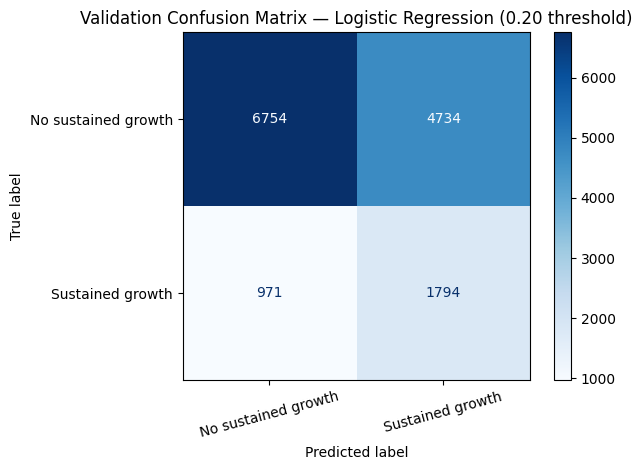

,Experiment,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,Average_Precision,Predicted_Positive
2,Standard Logistic Regression,0.2,0.5997,0.2748,0.6488,0.3861,0.666,0.3412,6528
7,Standard Logistic Regression,0.5,0.8083,0.6065,0.0340,0.0644,0.666,0.3412,155


In [13]:
import matplotlib.pyplot as plt

y_val_pred_020 = (y_val_prob >= SELECTED_THRESHOLD).astype(int)
print("Validation classification report at threshold 0.20:")
print(classification_report(y_val, y_val_pred_020,
                            target_names=["No sustained growth", "Sustained growth"],
                            zero_division=0))
ConfusionMatrixDisplay.from_predictions(
    y_val, y_val_pred_020,
    display_labels=["No sustained growth", "Sustained growth"],
    values_format="d", cmap="Blues"
)
plt.title("Validation Confusion Matrix — Logistic Regression (0.20 threshold)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

display(threshold_table.loc[threshold_table["Threshold"].isin([0.20, 0.50])].round(4))

10. Interpret coefficients from the model we are actually presenting
What this does: Extracts coefficients from log_reg_model, the standard Logistic Regression, rather than from the separate class-weighted experiment. Numeric inputs were standardized, so their odds ratios describe a one-standard-deviation increase, conditional on other features. An odds ratio of 1.48 means approximately 48% greater odds, not 48 percentage points more probability.

Caution: Coefficients indicate associations, not causal effects. Because our one-hot encoder retains all categorical indicators while the classifier uses regularization, individual genre/type coefficients are not simple comparisons to a single omitted reference class. Do not label these coefficients causal 'drivers'.

Largest positive coefficients:


,Feature,Coefficient,Odds_Ratio
1,num__pre_listener_slope_12w,0.4038,1.4975
19,cat__primary_genre_metal,0.3348,1.3976
5,num__pre_repeat_listener_ratio,0.1169,1.1240
7,num__days_since_last_release,0.1015,1.1068
24,cat__primary_genre_rock,0.0369,1.0376
23,cat__primary_genre_reggae/afro,0.0321,1.0326
4,num__pre_listens_per_listener,0.0283,1.0287
17,cat__primary_genre_k-pop/j-pop,0.0265,1.0268
10,cat__release_type_Single,0.0098,1.0098
16,cat__primary_genre_jazz/blues,-0.0257,0.9746


Largest negative coefficients:


,Feature,Coefficient,Odds_Ratio
6,num__n_prior_releases,-0.1191,0.8877
18,cat__primary_genre_latin,-0.1426,0.8671
12,cat__primary_genre_country,-0.1500,0.8607
22,cat__primary_genre_r&b/soul,-0.1818,0.8338
11,cat__primary_genre_classical/soundtrack,-0.2303,0.7943
13,cat__primary_genre_electronic,-0.2478,0.7805
0,num__pre_listeners_12w,-0.2591,0.7717
15,cat__primary_genre_hip-hop,-0.2981,0.7423
9,cat__release_type_EP,-0.4428,0.6423
8,cat__release_type_Album,-0.6204,0.5377


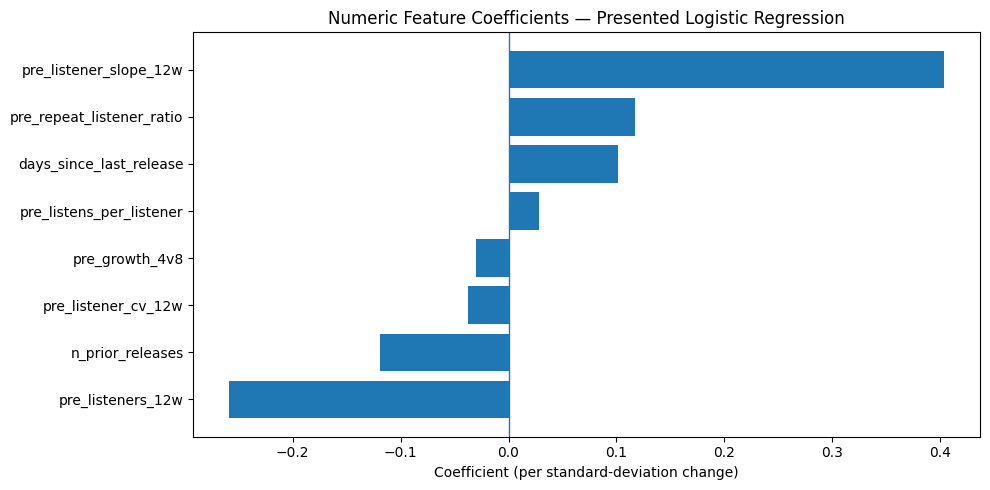

In [14]:
fitted_preprocessor = log_reg_model.named_steps["preprocessor"]
feature_names = fitted_preprocessor.get_feature_names_out()
coefs = log_reg_model.named_steps["classifier"].coef_.ravel()
coef_table = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefs,
    "Odds_Ratio": np.exp(coefs),
}).sort_values("Coefficient", ascending=False)
print("Largest positive coefficients:")
display(coef_table.head(10).round(4))
print("Largest negative coefficients:")
display(coef_table.tail(10).round(4))

numeric_coefs = coef_table[coef_table["Feature"].str.startswith("num__")].copy()
numeric_coefs["Feature"] = numeric_coefs["Feature"].str.replace("num__", "", regex=False)
numeric_coefs = numeric_coefs.sort_values("Coefficient")
plt.figure(figsize=(10, 5))
plt.barh(numeric_coefs["Feature"], numeric_coefs["Coefficient"])
plt.axvline(0, linewidth=1)
plt.title("Numeric Feature Coefficients — Presented Logistic Regression")
plt.xlabel("Coefficient (per standard-deviation change)")
plt.tight_layout()
plt.show()

11. Final test evaluation — run only with the complete dataset
What this does: After fixing the model and threshold using validation data, evaluates once on the later (2025+) test releases. Do not tune the threshold or features using these results. The cell deliberately refuses to run if the current file is not the complete 112,415-row version, because an earlier Colab copy was missing 3,385 test rows.

The test metrics may differ from validation: this is a genuine out-of-time check, not a mistake.

Held-out test results (2025+; clean releases):


,Experiment,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,Average_Precision,Predicted_Positive
0,Final held-out test,0.2,0.6087,0.3338,0.6558,0.4424,0.6731,0.3929,10883


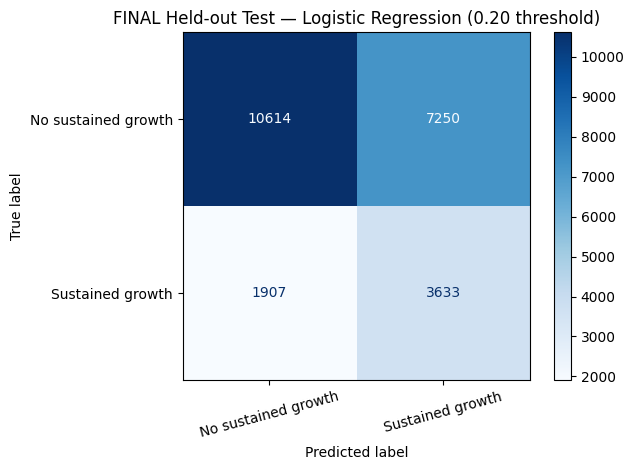

In [15]:
EXPECTED_SPLITS = {"train": 53593, "val": 22782, "test": 36040}
actual_splits = df["split"].value_counts().to_dict()
if len(df) != 112415 or any(actual_splits.get(k) != v for k, v in EXPECTED_SPLITS.items()):
    print("FINAL TEST NOT RUN: use the complete 112,415-row dataset first.")
else:
    y_test_prob = log_reg_model.predict_proba(X_test)[:, 1]
    final_test_metrics = pd.DataFrame([
        metric_row(y_test, y_test_prob, SELECTED_THRESHOLD, "Final held-out test")
    ])
    print("Held-out test results (2025+; clean releases):")
    display(final_test_metrics.round(4))
    ConfusionMatrixDisplay.from_predictions(
        y_test, (y_test_prob >= SELECTED_THRESHOLD).astype(int),
        display_labels=["No sustained growth", "Sustained growth"],
        values_format="d", cmap="Blues"
    )
    plt.title("FINAL Held-out Test — Logistic Regression (0.20 threshold)")
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

Research question: Can pre-release artist and release features help predict whether listening growth remains sustained after release?

Current model: Standard, regularized Logistic Regression using 10 pre-release features, trained on clean releases from the training period. Classifications use the provisional 0.20 probability threshold selected with validation data.

Preliminary validation results from the earlier exploratory notebook: At threshold 0.20, precision ≈ 0.275, recall ≈ 0.649, F1 ≈ 0.386, ROC-AUC ≈ 0.666, and AP ≈ 0.341. Regenerate all metrics above to confirm they match the exact CSV you use. The model identifies more sustained-growth releases than at threshold 0.50, at the cost of many false alarms.

Interpretation: The direction and size of coefficients indicate associations after controlling for other included features. The initial model shows only modest ability to distinguish sustained from non-sustained growth; it should not be described as a high-accuracy forecasting tool merely because most releases are classified as negative.

Limitations and next steps: The dataset represents ListenBrainz listeners, not the full streaming population; the design is observational; genre metadata may not be historical; clean-release filtering limits applicability; and repeated artists across periods may create dependence. Future work: check feature leakage/time availability, evaluate calibration, compare against simple baselines, test additional pre-release features and regularization, and examine performance for cold-start artists. Preserve the later test period for final model selection.

Suggested presentation line: “I trained an interpretable Logistic Regression baseline to predict sustained listener growth using 10 pre-release features. I compared prediction cutoffs on 2024 validation data and selected 0.20 as a provisional threshold to increase recall. I report precision, recall, F1, ROC-AUC, average precision, and a confusion matrix, and I interpret coefficients as associations rather than causal effects.”